
## Metropolis MC of surface step
*Massimiliano Solero (2026)* 


Verrà simulata, attraverso tecniche Monte Carlo, la crescita di uno step nella direzione [100] su una
superficie di Kossel (100). Il cristallo di Kossel è un cristallo cubico con una molecola per cella
reticolare con un valore di legame fisso (ϵ) con le celle adiacenti nelle tre dimensioni, Solid-On-
Solid (SOS). All’equilibrio termodinamico e con una temperatura maggiore di zero lo scalino non
è perfettamente lineare ma ha alcune protuberanze (dette ”kinks”) e step-adatomi. All’interno di
questa relazione verrà studiato solamente un modello bidimensionale e verranno trattate solamente
le due tipologie di modifiche dello scalino appena descritte, altre tipologie di modifiche non verranno
indagate.

---
**ENG**

The growth of a step in the [100] direction on a Kossel (100) surface will be simulated using Monte Carlo techniques. The Kossel crystal is a cubic crystal with one molecule per lattice cell with a fixed bond value (ϵ) with adjacent cells in the three dimensions, Solid-On-Solid (SOS). At thermodynamic equilibrium and at a temperature greater than zero, the step is not perfectly straight but exhibits some protrusions (called “kinks”) and step-adatoms. Within this report, only a two-dimensional model will be studied, and only the two types of step modifications just described will be considered; other types of modifications will not be investigated.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from f2py_jit import jit
import os

## 1. Configurazione sistema

- l: lunghezza dello step
- T: temperatura
- nsteps: numero dei passi della catena markoviana fatti (se si inserisce anche nsteps_eq, sono gli step del campionamento dopo la fase di termalizzazione)
- nsteps_eq: numero dei passi per l'equilibratura (INSERIRE QUESTO VALORE PER CALCOLARE L'AUTOCORRELAZIONE)
- num_part: numero di particelle
- nblk_pts: numero di punti nel grafico delle medie a blocchi
- seed_init: seed dedicato all'inizializzazione del sistema
- seed_mc: seed dedicato allo sviluppo MC del sistema

---

**ENG**

1. System configuration

- l: step length
- T: temperature
- nsteps: number of steps of the Markov chain performed (if nsteps_eq is also set, these are the sampling steps after the thermalization phase)
- nsteps_eq: number of steps for equilibration (SET THIS VALUE TO COMPUTE THE AUTOCORRELATION)
- num_part: number of particles
- nblk_pts: number of points in the block average plot
- seed_init: seed dedicated to the initialization of the system
- seed_mc: seed dedicated to the MC evolution of the system


In [2]:
f90_mc = jit('simulation_step.f90', flags='-O3 -ffast-math', inline=False, verbose = False)

l = 100
T = 0.4
nsteps = 100000
nsteps_eq = 5000
num_part = 105
nblk_pts = 100
seed_init = 18546478
seed_mc = 78557116

## 2. Dinamica Monte Carlo e risultati preliminari
Scelta della mossa, salvataggio dati e grafici

## Tipologie di mossa MC

- **single_particle_move**: ad ogni step si sceglie casualmente una colonna e, se occupata, si sposta una particella verso destra o sinistra con probabilità 1/2; la mossa viene accettata secondo l'algoritmo di Metropolis. Se la colonna scelta è vuota la configurazione resta invariata.
- **single_particle_move_ratio**: variante della mossa precedente in cui, per rispettare il bilancio dettagliato, si campiona solo tra le colonne occupate; il peso di Metropolis viene corretto con il rapporto N_occ,old/N_occ,new tra il numero di colonne occupate prima e dopo la mossa.
- **single_particle_move2T**: stessa dinamica della mossa a probabilità bilanciata, ma con una probabilità di accettazione P = exp(−ΔE/2T); equivale, nei risultati, a un Metropolis ordinario a temperatura doppia.
- **nfold_move**: algoritmo n-fold way (Bortz–Kalos–Lebowitz) a tempo continuo; le mosse possibili sono suddivise in 5 classi secondo ΔE ∈ {−2,−1,0,1,2}, si estrae la classe e la colonna proporzionalmente al rate totale R_tot, e si avanza il tempo simulato di dt = −ln(rnd)/R_tot. Elimina i tentativi rifiutati e riduce drasticamente tempi di termalizzazione e autocorrelazione, specialmente a basse T.
- **changing_number_particle**: il numero di particelle non è conservato. Ad ogni step si decide casualmente se aggiungere (sempre accettata, P₊ = 1) o rimuovere una particella da una colonna occupata, con probabilità P₋ = exp(−ΔE/T) corretta dal fattore N_old/N_new per il bilancio dettagliato. Richiede tempi di equilibratura molto più lunghi e mostra un andamento meno regolare delle osservabili.

---

**ENG**

2.Monte Carlo dynamics and results

Choice of the move, data saving and plots

## MC move types

- **single_particle_move**: at each step a column is chosen at random and, if occupied, one particle is moved left or right with probability 1/2; the move is accepted with the standard Metropolis criterion. If the chosen column is empty the configuration is left unchanged.
- **single_particle_move_ratio**: variant of the move above where, to satisfy detailed balance, sampling is restricted to occupied columns only; the Metropolis weight is corrected by the ratio N_occ,old/N_occ,new between the number of occupied columns before and after the move.
- **single_particle_move2T**: same dynamics as the balanced-probability move, but with acceptance probability P = exp(−ΔE/2T); it reproduces the results of an ordinary Metropolis scheme at twice the temperature.
- **nfold_move**: continuous-time n-fold way algorithm (Bortz–Kalos–Lebowitz); possible moves are split into 5 classes according to ΔE ∈ {−2,−1,0,1,2}, the class and column are drawn proportionally to the total rate R_tot, and simulated time is advanced by dt = −ln(rnd)/R_tot. It removes rejected attempts and drastically shortens thermalization and autocorrelation times, especially at low T.
- **changing_number_particle**: the number of particles is not conserved. At each step a particle is randomly added (always accepted, P₊ = 1) to or removed from an occupied column, with removal probability P₋ = exp(−ΔE/T) corrected by the factor N_old/N_new to satisfy detailed balance. It requires much longer equilibration times and shows a less regular behaviour of the observables.

0.3736857142857143


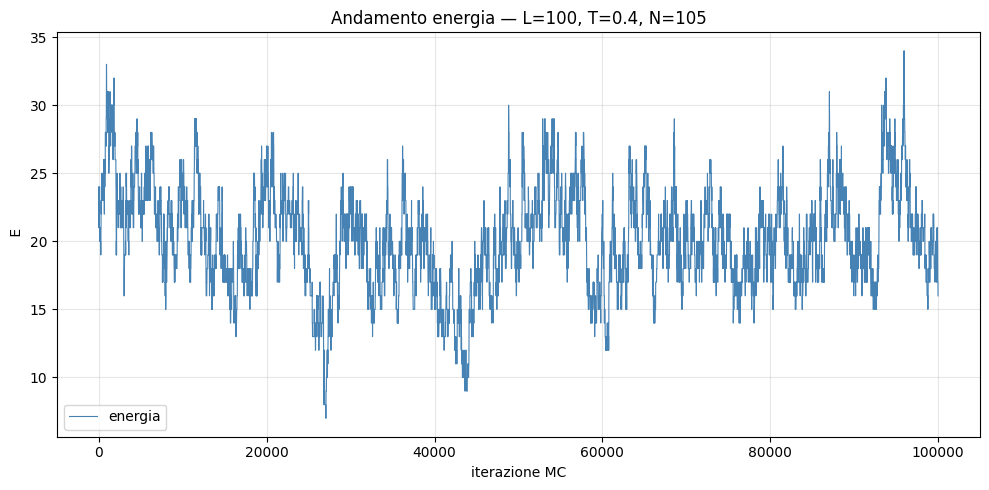

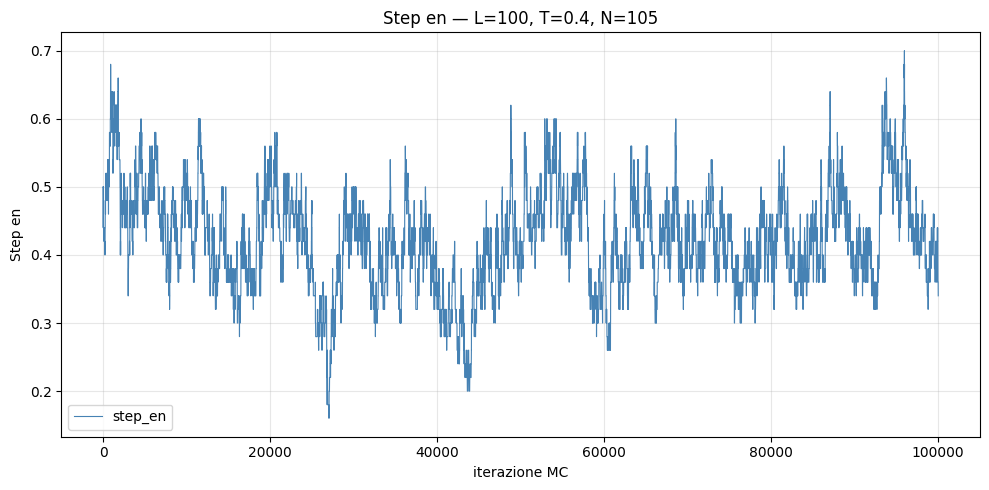

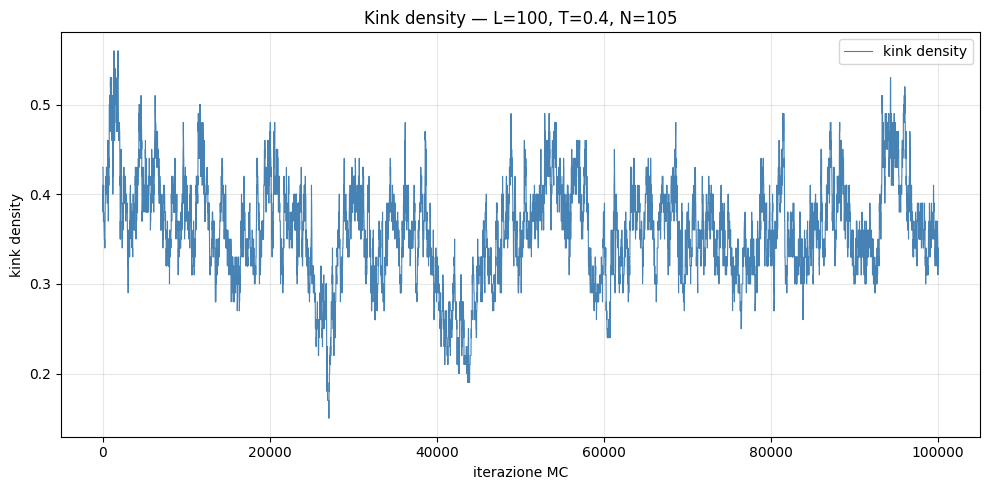

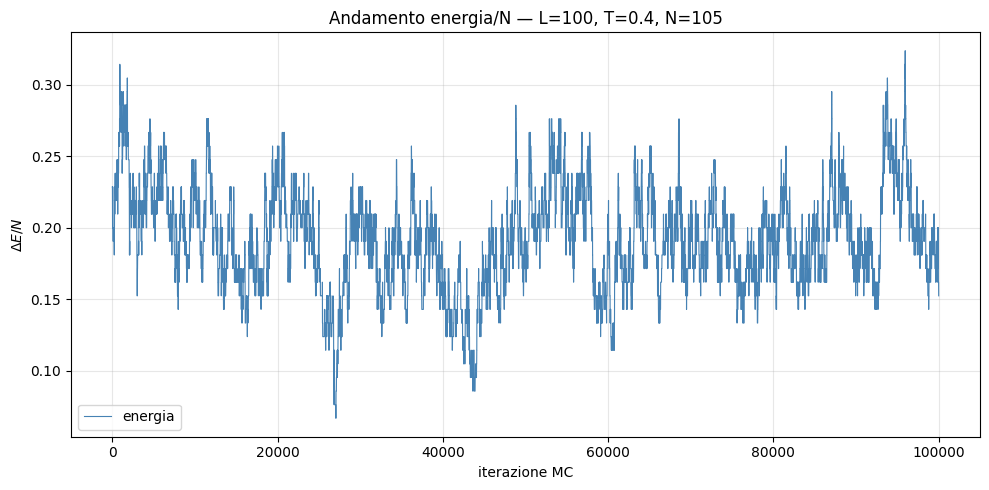

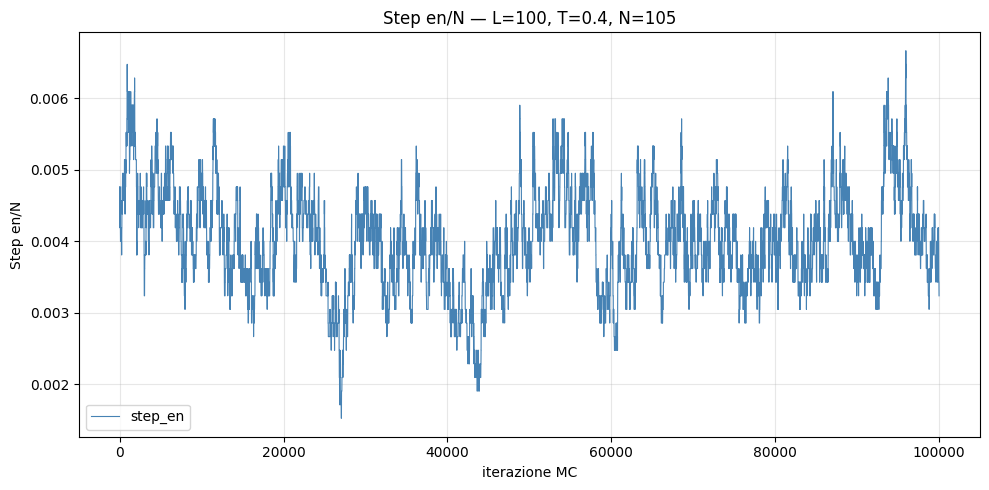

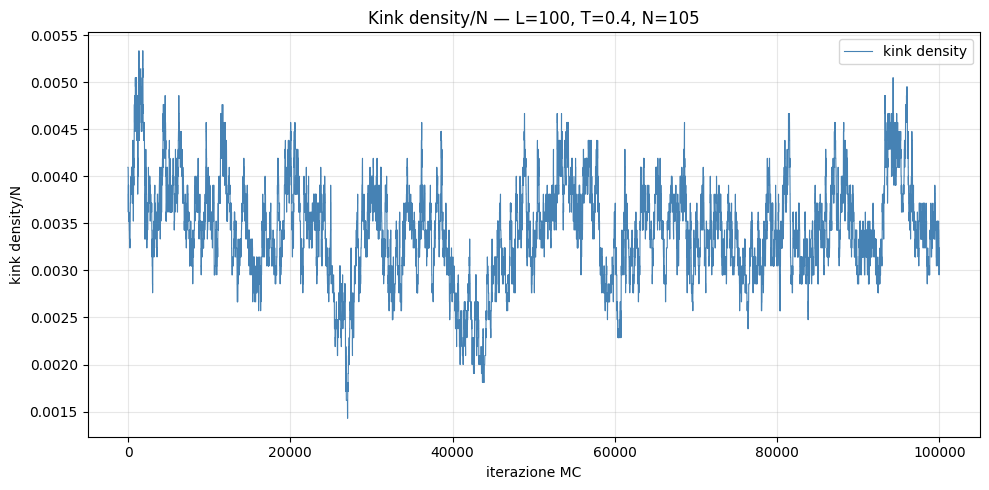

In [ ]:
move_type = "single_particle_move"
result = f90_mc.main.simulation(l, T, nsteps, nsteps_eq, num_part, move_type, seed_init, seed_mc, nblk_pts)
step_final = result[0]
kink_dens = result[1]
step_en = result[2]
energy = result[3]
mean_len = result[4]
acceptance_prob = result[5]
acceptance_prob1 = result[6]
aut_energy = result[7]
aut_kink_den = result[8]
aut_step_en = result[9]
dt = result[10]
err_e = result[11]
err_kink = result[12]
err_step_e = result[13]
blockstep_arr = result[14] 

print(acceptance_prob)

if move_type == "changing_number_particle":
    N = mean_len * l   
    n_label = f"N start={num_part}"
else:
    N = num_part
    n_label = f"N={num_part}"

if move_type == "nfold_move":
    t = np.cumsum(dt)      
    xlabel = "tempo (unità di simulazione)"
    w = dt[1:]
    mean_E = np.sum(energy[:-1]*w)/np.sum(w)
    mean_kink = np.sum(kink_dens[:-1]*w)/np.sum(w)
    mean_step = np.sum(step_en[:-1]*w)/np.sum(w)
else:
    t = np.arange(1, nsteps + 1)
    xlabel = "iterazione MC"


fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(t, energy, color='steelblue', linewidth=0.8, label='energia')
#ax.axhline(np.mean(energy), color='red', linestyle='--', linewidth=1.5, label=f'media = {np.mean(energy):.3f}')
ax.set_xlabel(xlabel)
ax.set_ylabel(' E')
ax.set_title(f'Energia — L={l}, T={T}, {n_label}')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(t, step_en, color='steelblue', linewidth=0.8, label='step_en')
#ax.axhline(np.mean(step_en), color='red', linestyle='--', linewidth=1.5, label=f'media = {np.mean(step_en):.3f}')
ax.set_xlabel(xlabel)
ax.set_ylabel('Step en')
ax.set_title(f'Step en — L={l}, T={T}, {n_label}')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
# plt.savefig('energy_mc.png', dpi=150)
plt.show()

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(t, kink_dens, color='steelblue', linewidth=0.8, label='kink density')
#ax.axhline(np.mean(kink_dens), color='red', linestyle='--', linewidth=1.5, label=f'media = {np.mean(kink_dens):.3f}')
ax.set_xlabel(xlabel)
ax.set_ylabel('kink density')
ax.set_title(f'Kink density — L={l}, T={T}, {n_label}')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
# plt.savefig('energy_mc.png', dpi=150)
plt.show()

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(t, energy/N, color='steelblue', linewidth=0.8, label='energia')
#ax.axhline(np.mean(energy), color='red', linestyle='--', linewidth=1.5, label=f'media = {np.mean(energy):.3f}')
ax.set_xlabel(xlabel)
ax.set_ylabel('$\\Delta E/N$')
ax.set_title(f'Energia/N — L={l}, T={T}, {n_label}')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(t, step_en/N, color='steelblue', linewidth=0.8, label='step_en')
#ax.axhline(np.mean(step_en), color='red', linestyle='--', linewidth=1.5, label=f'media = {np.mean(step_en):.3f}')
ax.set_xlabel(xlabel)
ax.set_ylabel('Step en/N')
ax.set_title(f'Step en/N — L={l}, T={T}, {n_label}')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
# plt.savefig('energy_mc.png', dpi=150)
plt.show()

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(t, kink_dens/N, color='steelblue', linewidth=0.8, label='kink density')
#ax.axhline(np.mean(kink_dens), color='red', linestyle='--', linewidth=1.5, label=f'media = {np.mean(kink_dens):.3f}')
ax.set_xlabel(xlabel)
ax.set_ylabel('kink density/N')
ax.set_title(f'Kink density/N — L={l}, T={T}, {n_label}')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
# plt.savefig('energy_mc.png', dpi=150)
plt.show()

## 3. Salvataggio file, autocorrelazione e media a blocchi
Verificare il nome della cartella di salvataggio dei dati (se non esiste verrà creata).

Risultati sull'autocorrelazione e sulle medie a blocchi: ricordare di osservare questi risultati solamente quando il sistema ha superato la fase di equilibratura (nsteps_eq da inserire nella prima cella osservando l'andamento dei grafici sopra).

---

**ENG**

3.File saving, autocorrelation and block averaging

Check the name of the folder where the data is saved (it will be created if it does not exist).

Results on the autocorrelation and on the block averages: remember to look at these results only once the system has passed the equilibration phase (nsteps_eq to be set in the first cell by looking at the trend of the plots above).

/tmp/ipykernel_106278/2226512818.py:9: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[0].legend()
/tmp/ipykernel_106278/2226512818.py:17: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[1].legend()
/tmp/ipykernel_106278/2226512818.py:25: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[2].legend()


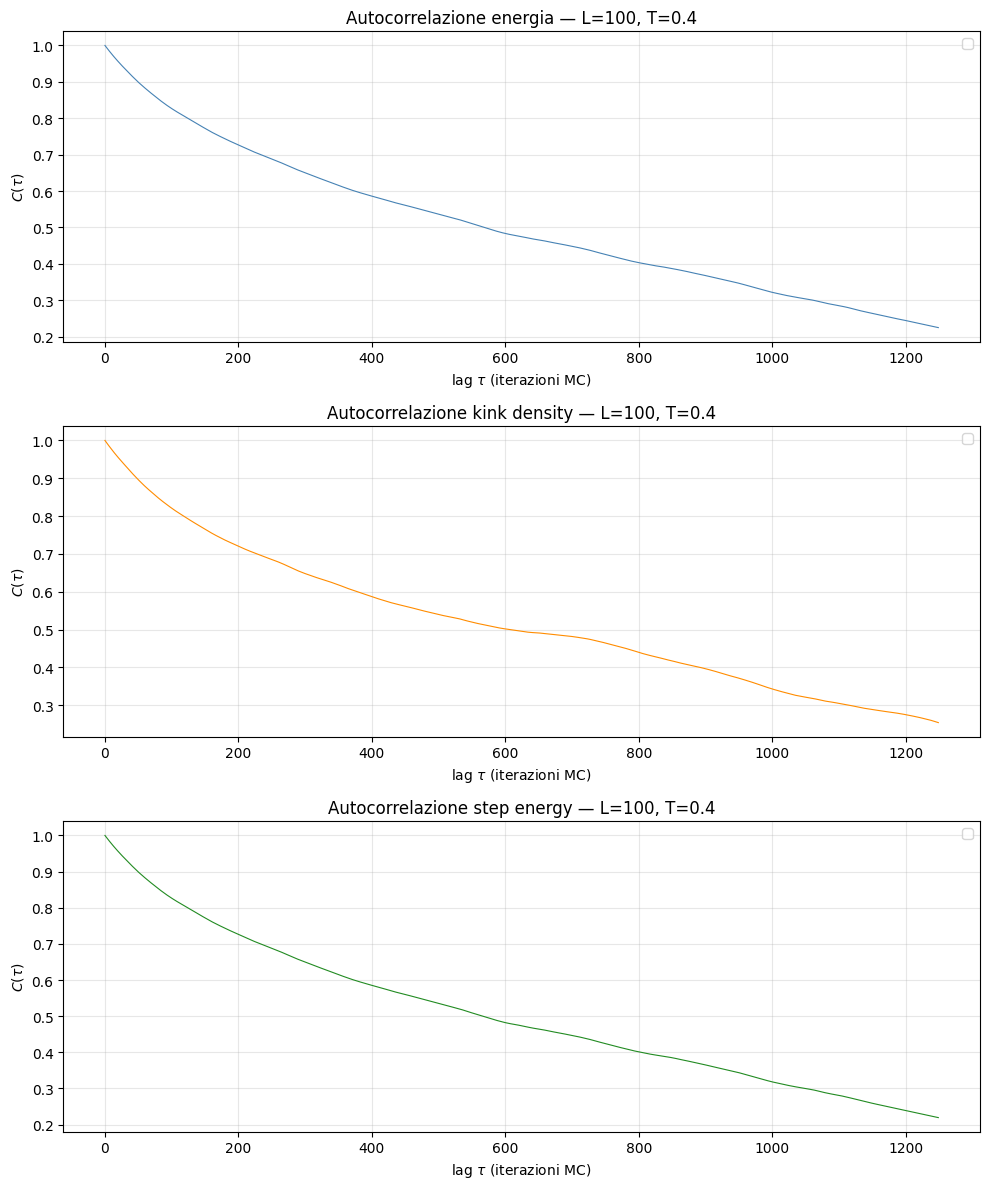

Dati salvati in: mc_changing_data1/run_L100_T0.400_N105_single_particle_move_seed18546478-78557116.npz


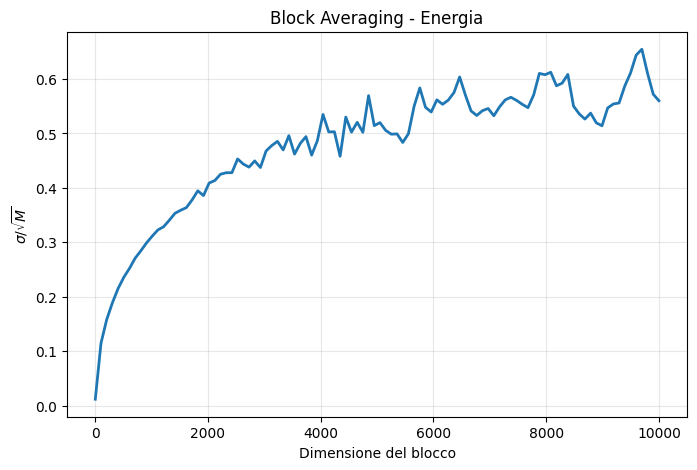

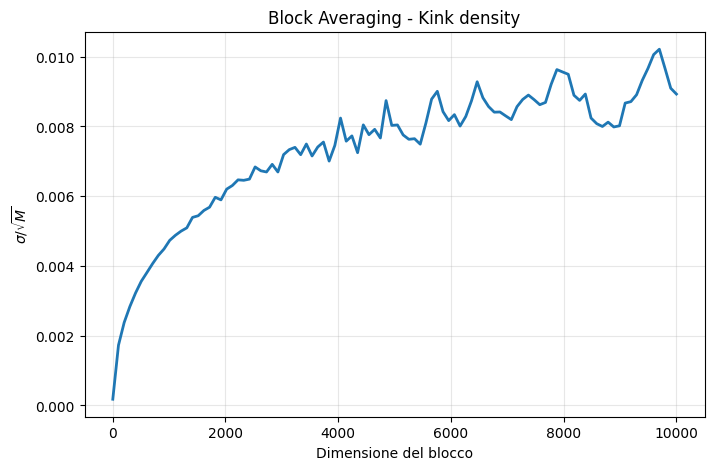

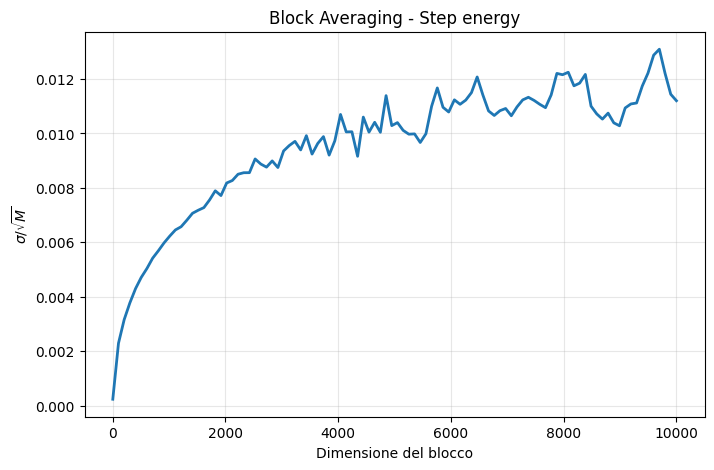

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(10, 12))
lags = np.arange(0, len(aut_energy))

axes[0].plot(lags, aut_energy, color='steelblue', linewidth=0.8)
#axes[0].axhline(0, color='red', linestyle='--', linewidth=1.0)
axes[0].set_xlabel('lag $\\tau$ (iterazioni MC)')
axes[0].set_ylabel('$C(\\tau)$')
axes[0].set_title(f'Autocorrelazione energia — L={l}, T={T}')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(lags, aut_kink_den, color='darkorange', linewidth=0.8)
#axes[1].axhline(0, color='red', linestyle='--', linewidth=1.0)
axes[1].set_xlabel('lag $\\tau$ (iterazioni MC)')
axes[1].set_ylabel('$C(\\tau)$')
axes[1].set_title(f'Autocorrelazione kink density — L={l}, T={T}')
axes[1].legend()
axes[1].grid(alpha=0.3)

axes[2].plot(lags, aut_step_en, color='forestgreen', linewidth=0.8)
#axes[2].axhline(0, color='red', linestyle='--', linewidth=1.0)
axes[2].set_xlabel('lag $\\tau$ (iterazioni MC)')
axes[2].set_ylabel('$C(\\tau)$')
axes[2].set_title(f'Autocorrelazione step energy — L={l}, T={T}')
axes[2].legend()
axes[2].grid(alpha=0.3)

plt.tight_layout()
#plt.savefig('autocorrelation.png', dpi=150)
plt.show()

# verificare nome cartella
outdir = "mc_changing_data1"
os.makedirs(outdir, exist_ok=True)
 
run_tag = f"L{l}_T{T:.3f}_N{num_part}_{move_type}_seed{seed_init}-{seed_mc}"
outpath = os.path.join(outdir, f"run_{run_tag}.npz")

np.savez(
    outpath,
    l=l,
    T=T,
    nsteps=nsteps,
    nsteps_eq=nsteps_eq,
    num_part=num_part,
    move_type=move_type,
    seed_init=seed_init,
    seed_mc=seed_mc,
    step_final=step_final,
    kink_dens=kink_dens,
    step_en=step_en,
    energy=energy,
    dt=dt,
    mean_len=mean_len,
    acceptance_prob=acceptance_prob,
    acceptance_prob1=acceptance_prob1,
    aut_energy=aut_energy,
    aut_kink_den=aut_kink_den,
    aut_step_en=aut_step_en,
    err_e=err_e,
    err_kink=err_kink,
    err_step_e=err_step_e,
    blockstep_arr=blockstep_arr
)

print(f"Dati salvati in: {outpath}")

fig, ax = plt.subplots(figsize=(8,5))
ax.plot(blockstep_arr, err_e, lw=2)
ax.set_xlabel("Dimensione del blocco")
ax.set_ylabel(r"$\sigma / \sqrt{M}$")
ax.set_title("Block Averaging - Energia")
ax.grid(alpha=0.3)
plt.show()


fig, ax = plt.subplots(figsize=(8,5))
ax.plot(blockstep_arr, err_kink, lw=2)
ax.set_xlabel("Dimensione del blocco")
ax.set_ylabel(r"$\sigma / \sqrt{M}$")
ax.set_title("Block Averaging - Kink density")
ax.grid(alpha=0.3)
plt.show()


fig, ax = plt.subplots(figsize=(8,5))
ax.plot(blockstep_arr, err_step_e, lw=2)
ax.set_xlabel("Dimensione del blocco")
ax.set_ylabel(r"$\sigma / \sqrt{M}$")
ax.set_title("Block Averaging - Step energy")
ax.grid(alpha=0.3)
plt.show()